# PA-S1 · KKBox: продуктовая аналитика подписки музыкального стриминга

**Дисциплина:** Продуктовая аналитика, МГТУ им. Н.Э. Баумана · **Трек Б (индивидуальный)** · Осень 2026

**Автор:** Еременко Даниил · **Репозиторий:** [_kkbox-product-analytics_](https://github.com/iongyy/kkbox-product-analytics)

Ноутбук выполняется от начала до конца (Kernel → Restart & Run All). Все пути относительные, данные — в папке `data/`.

## 1. Продукт

**Что делаем.** KKBox — музыкальный стриминг-сервис по подписке (Тайвань, рынки Восточной Азии), каталог 30+ млн треков, упор на азиатскую поп-музыку.

**Для кого.** Слушатели 15–35 лет, преимущественно мобильные пользователи, которым важен локальный музыкальный каталог.

**Проблема.** Легальный и удобный доступ к азиатской музыке: офлайн-прослушивание, отсутствие рекламы, персональные рекомендации. Альтернативы пользователя — пиратские источники и разовые покупки треков.

**Гипотеза ценности.** Безлимитный стриминг за фиксированную ежемесячную плату удерживает слушателя дольше и приносит больше выручки, чем бесплатная версия с рекламой, — если сервис регулярно возвращает пользователя к прослушиванию.

**Бизнес-модель.** Подписка: планы 7 / 30 / 90 / 180+ дней (медианный чек ≈ 149 NTD/мес), автопродление по умолчанию, freemium-витрина с рекламой как источник конверсии в платную подписку.

## 2. Данные

**Источник.** Открытый датасет конкурса [WSDM — KKBox's Churn Prediction Challenge (Kaggle, 2017)](https://www.kaggle.com/c/kkbox-churn-prediction-challenge/data). Реальные обезличенные данные KKBox.

**Лицензия.** Данные опубликованы по правилам конкурса Kaggle (использование в исследовательских/учебных целях, публичная перепубликация сырых данных не предполагается). Поэтому в репозиторий кладём только ноутбук и ссылку на источник; папка `data/` — в `.gitignore`.

**Состав (окно v1):**

| Файл | Содержимое | Строк | Размер |
|---|---|---|---|
| `members_v3.csv` | пользователи: город, возраст, пол, канал регистрации, дата регистрации | 6 769 473 | 0,4 ГБ |
| `transactions_v1.csv` | транзакции: план, цена, оплата, автопродление, отмена, даты | 21 547 746 | 1,6 ГБ |
| `user_logs_v1.csv` | дневные логи прослушиваний (треки, секунды) | ~0,5 млрд | 28 ГБ |
| `train_v1.csv` | метка оттока `is_churn` (нет продления 30 дней после окончания) | 992 931 | 45 МБ |

**Период.** 2015-01-01 — 2017-02-28 (≈ 26 месяцев, 790 дней). Метка оттока измерена на окне март 2017.

**Ограничения.**
- Нет данных о расходах на привлечение и себестоимости → CAC и маржа задаются допущениями (зафиксировано, согласуется с преподавателем).
- Нет контентных признаков (треки/жанры), география — один рынок (Тайвань).
- Файлы версии v2 (март 2017) в копии не распаковались; расчёты сделаны на v1, окно достаточное.

**Соответствие требованиям к датасету:**

| Требование | Факт | Статус |
|---|---|---|
| Пользователи с ID и датой появления | 6,77 млн | ✅ оптимум |
| Действия со временем | ~0,5 млрд дневных логов | ✅ оптимум |
| Платежи (сумма, дата) | 21,5 млн транзакций, 1,73 млн платящих | ✅ оптимум |
| Расходы на привлечение / маржа | нет | ❌ фиксируем ограничение |
| Ряд по дням | дневные логи, 790 дней | ✅ оптимум |
| Отток «нет события N дней» | 63 471 отточных (6,4%) по правилу 30 дней | ✅ оптимум |
| Срезы | канал `registered_via`, город, способ оплаты, тариф | ✅ 3+ |
| Реалистичные дефекты | пропуски, дубли, мусорный возраст, нулевые платежи | ✅ (раздел 3) |

## 3. Проверка качества данных

Проверяем пропуски, дубли, выбросы, тестовых/аномальных пользователей и границы времени.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')

DATA = 'data'
MEMBERS = os.path.join(DATA, 'members_v3.csv')
TRANSACTIONS = os.path.join(DATA, 'transactions_v1.csv')
USER_LOGS = os.path.join(DATA, 'user_logs_v1.csv')
TRAIN = os.path.join(DATA, 'train_v1.csv')

# Опциональный тяжёлый расчёт по user_logs (28 ГБ). По умолчанию выключен.
RUN_LOGS_SCAN = False
LOG_SAMPLE_USERS = 100_000

In [2]:
members = pd.read_csv(
    MEMBERS,
    dtype={'bd': 'int16', 'city': 'int8', 'registered_via': 'int8', 'gender': 'category'},
)
print(f'Строк: {len(members):,}; уникальных msno: {members.msno.nunique():,}')
print(f'Дубли msno: {members.msno.duplicated().sum():,}')
print(f'\nПропуски:\n{members.isna().sum().to_string()}')

bd_bad = (members.bd < 0) | (members.bd > 100)
print(f'\nbd == 0 (возраст не указан): {(members.bd == 0).sum():,} '
      f'({(members.bd == 0).mean():.1%})')
print(f'bd вне [0; 100] (мусорные значения, напр. -7168, 2016): {bd_bad.sum():,}')

print(f'\nДаты регистрации: {members.registration_init_time.min()} — '
      f'{members.registration_init_time.max()}')
future_reg = (members.registration_init_time > 20170228).sum()
print(f'Регистрации позже конца окна данных (2017-02-28): {future_reg:,} '
      f'(артефакт версии v3 файла)')
print(f'\nКаналы регистрации (registered_via):\n'
      f'{members.registered_via.value_counts().head(8).to_string()}')

Строк: 6,769,473; уникальных msno: 6,769,473


Дубли msno: 0



Пропуски:
msno                            0
city                            0
bd                              0
gender                    4429505
registered_via                  0
registration_init_time          0

bd == 0 (возраст не указан): 4,540,215 (67.1%)
bd вне [0; 100] (мусорные значения, напр. -7168, 2016): 5,651

Даты регистрации: 20040326 — 20170429
Регистрации позже конца окна данных (2017-02-28): 154,166 (артефакт версии v3 файла)

Каналы регистрации (registered_via):
registered_via
4     2793213
3     1643208
9     1482863
7      805895
11      25047
13       5455
8        3982
5        3115


In [3]:
tx = pd.read_csv(TRANSACTIONS, dtype={'msno': 'category'})  # category сразу: экономия памяти
print(f'Строк: {len(tx):,}; уникальных платящих/изменявших подписку: {tx.msno.nunique():,}')
print(f'Пропуски: {tx.isna().sum().sum()}')
print(f'Полные дубли строк: {tx.duplicated().sum():,}')
print(f'\nДаты транзакций: {tx.transaction_date.min()} — {tx.transaction_date.max()}')
print(f'Даты окончания подписки: {tx.membership_expire_date.min()} — '
      f'{tx.membership_expire_date.max()}')
print(f'  в т.ч. expire = 19700101 (артефакт): '
      f'{(tx.membership_expire_date == 19700101).sum():,}')
print(f'\nСумма <= 0 (триалы/промо/возвраты): {(tx.actual_amount_paid <= 0).sum():,}')
print(f'План 0 дней: {(tx.payment_plan_days <= 0).sum():,}')
print(f'Оплачено > прайса (расхождение скидок/наценок): '
      f'{(tx.actual_amount_paid > tx.plan_list_price).sum():,}')
print(f'\nДоля отмен (is_cancel): {tx.is_cancel.mean():.2%}')
print(f'Доля автопродлений (is_auto_renew): {tx.is_auto_renew.mean():.2%}')

Строк: 21,547,746; уникальных платящих/изменявших подписку: 2,363,626


Пропуски: 0


Полные дубли строк: 3,339

Даты транзакций: 20150101 — 20170228
Даты окончания подписки: 19700101 — 20170331
  в т.ч. expire = 19700101 (артефакт): 1,776

Сумма <= 0 (триалы/промо/возвраты): 1,196,876


План 0 дней: 870,124
Оплачено > прайса (расхождение скидок/наценок): 857,422

Доля отмен (is_cancel): 3.98%
Доля автопродлений (is_auto_renew): 85.20%


**Выводы по качеству.**
- `gender` отсутствует у 65% пользователей, `bd` (возраст) у 67% равен 0, а ~5,7 тыс. значений — мусорные (от −7168 до 2016): демографию используем только как грубый срез, в моделях возраст не доверяем.
- Полных дублей транзакций всего 3 339 (0,015%) — удаление не влияет на расчёты, оставляем как есть.
- Нулевые суммы (5,6% строк) и планы 0 дней (4,0%) — триалы/промо: для денежных метрик фильтруем `actual_amount_paid > 0`.
- Часть `membership_expire_date` = 1970-01-01 — технический артефакт, исключаем из анализа сроков.
- Тестовых пользователей явного флага нет; аномалии (мусорный возраст, будущие даты регистрации) носят массовый, а не точечный характер — отдельной чистки не требуется.
- Границы времени жёсткие: 2015-01-01 — 2017-02-28; когорты 2017-01 и 2017-02 исключаем из retention (нет периода наблюдения), частичная правая цензура начиная с когорты 2016-04 маскируется.

Датасет подходит: есть различимый пользователь, платежи, активность, канал, готовое правило оттока и реалистичные дефекты. Единственный пробел — расходы на привлечение (ограничение для CAC).

## 4. Определения (фиксируются и не меняются в следующих сдачах)

- **Активный пользователь** — пользователь с валидной подпиской (`membership_expire_date` ≥ текущей даты) или хотя бы одним днём прослушивания (`user_logs`) в рассматриваемом периоде.
- **Активный платящий подписчик** — пользователь, чья оплаченная подписка валидна в рассматриваемом месяце (`membership_expire_date` покрывает месяц). Владелец 90-дневного плана — платящий подписчик все 3 месяца, а не только в месяц оплаты.
- **Конверсия** — доля зарегистрировавшихся в окне наблюдения пользователей, совершивших первую оплату не раньше месяца регистрации (`registration → first transaction`).
- **Когорта** — группа пользователей по месяцу первой оплаченной транзакции (активации платежа).
- **Подписочное удержание (retention, основное)** — доля когорты, чья подписка валидна в m-м месяце после месяца первой транзакции (по `membership_expire_date`).
- **Платёжное удержание (диагностическое)** — доля когорты, совершившая оплаченную транзакцию (`actual_amount_paid > 0`, `payment_plan_days > 0`) в m-м месяце; занижено для длинных планов (90/180+ дней), поэтому не является мерой удержания само по себе.
- **Отток (churn)** — отсутствие новой валидной подписки в течение 30 дней после окончания текущей (официальное правило конкурса; метка `is_churn` в `train_v1.csv`).

> Erratum S1 (по итогам методологического разбора): определения активного платящего подписчика и удержания уточнены — первичная редакция считала подписчика по событию оплаты, что занижало MAPU и retention для длинных планов. Далее в ноутбуке используются уточнённые определения.

> В этой сдаче расчёты ведутся по транзакциям; логи прослушиваний (`user_logs`, 28 ГБ) подключаются к расчётам со следующих сдач — определение активного пользователя менять не потребуется.

## 5. Метрики (пирамида)

| Уровень | Метрика | Зачем | Решение, которое на неё опирается |
|---|---|---|---|
| **North Star** | Активные платящие подписчики в месяц (MAPU, по валидности подписки) | Одновременно отражает рост, монетизацию и удержание — главный драйвер выручки подписки | Оценка эффекта любых продуктовых изменений на бизнес |
| Диагностическая 1 | M3 подписочное удержание новых когорт | Ранний сигнал качества привлечения и онбординга | Оценка каналов и промо-кампаний, решение об их масштабировании |
| Диагностическая 2 | ARPPU в месяц (NTD) | Ценность одного подписчика | Изменение тарифной сетки и скидочной политики |
| Риск-метрика | Churn на экспирации (нет продления 30 дней после окончания, train) + доля отмен `is_cancel` | Рост churn обесценивает привлечение; отмены — опережающий индикатор | Стоп-фактор для закупки трафика, запуск retention-кампаний |

## 6. Трекинг

| Событие | Триггер | Параметры | Метрика | Этап пути | Поле датасета |
|---|---|---|---|---|---|
| `registration` | первое появление пользователя | канал, город, дата | конверсия рег.→оплата, MAPU | Acquisition | `members_v3.registration_init_time`, `registered_via`, `city` |
| `payment` | оплата или продление плана | сумма, план (дней), способ оплаты | ARPPU, retention, LTV | Revenue | `transactions_v1.actual_amount_paid`, `payment_plan_days`, `payment_method_id` |
| `listen_day` | прослушивания в течение дня | треков >25/50/75/98.5%, уникальных треков, секунды | вовлечённость, DAU | Retention | `user_logs_v1.date`, `num_unq`, `total_secs` |
| `cancel` | ручная отмена автопродления | бинарный флаг | риск-метрика (churn) | Retention | `transactions_v1.is_cancel` |
| `churn_30d` | нет продления в течение 30 дней после окончания подписки | бинарная метка | churn, North Star | Churn | `train_v1.is_churn` |

Каждое событие привязано к метрике и к конкретному полю датасета; события покрывают полный путь пользователя.

### 7.1. Когортный retention: платёжная и подписочная кривые

Когорта — месяц первой оплаченной транзакции. Считаем две кривые: **платёжную** (доля когорты с оплатой в месяце m — занижена для длинных планов) и **подписочную** (доля когорты с валидной подпиской по `membership_expire_date` — основная). Когорта 2015-01 исключена из-за левой цензуры (в ней накоплены все платившие до 2015 года: 549 тыс. пользователей против ~50 тыс. у соседних когорт), когорты 2017-01/2017-02 — из-за отсутствия периода наблюдения; частичная правая цензура маскируется.

In [4]:
# Только оплаченные транзакции (по определению активного платящего подписчика)
paid = (tx.actual_amount_paid > 0) & (tx.payment_plan_days > 0)
txm = tx.loc[paid, ['msno', 'transaction_date']].copy()
txm['month'] = txm.transaction_date // 100  # YYYYMM как int

first = txm.groupby('msno', observed=True)['month'].min().rename('cohort')
pairs = txm[['msno', 'month']].drop_duplicates().join(first, on='msno')

def month_diff(a, b):
    """Разница в месяцах между датами в формате YYYYMM (int)."""
    return (a // 100 - b // 100) * 12 + (a % 100 - b % 100)

pairs['m'] = month_diff(pairs['month'], pairs['cohort'])
# 2015-01 исключаем: левая цензура (накоплены платившие до 2015 года)
pairs = pairs[(pairs.cohort >= 201502) & (pairs.cohort <= 201612) & pairs.m.between(0, 11)]

cnt = pairs.groupby(['cohort', 'm']).size()
size = pairs.drop_duplicates('msno').groupby('cohort').size()
ret = (cnt / size).unstack()

# Маска ячеек за пределами окна данных (правая цензура)
MAX_MONTH = 201702
censored = pd.DataFrame(
    {c: [month_diff(MAX_MONTH, co) < c for co in ret.index] for c in ret.columns},
    index=ret.index,
)
ret = ret.mask(censored)
ret.index = ret.index.astype(str).str[:4] + '-' + ret.index.astype(str).str[4:]
ret.columns = [f'M{c}' for c in ret.columns]
print(f'Когорт: {len(ret)}, пользователей в них: {size.sum():,}')
# Взвешенные средние (вес — размер когорты) рядом с невзвешенными
for m, col in ((1, 'M1'), (3, 'M3'), (6, 'M6')):
    c = ret[col].dropna()
    w = np.average(c, weights=[size[int(k.replace('-', ''))] for k in c.index])
    print(f'{col}: взвешенный {w:.1%}, невзвешенный {c.mean():.1%}')
(ret * 100).round(1)

Когорт: 23, пользователей в них: 1,126,482
M1: взвешенный 66.5%, невзвешенный 64.6%
M3: взвешенный 61.9%, невзвешенный 60.4%
M6: взвешенный 60.4%, невзвешенный 57.9%


,M0,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11
cohort,,,,,,,,,,,,
2015-02,100.00,49.40,34.60,23.80,38.60,38.50,42.20,41.10,34.50,36.40,35.90,33.30
2015-03,100.00,31.70,22.90,38.10,37.10,35.60,40.30,35.10,35.40,34.20,31.90,29.00
2015-04,100.00,23.50,42.40,42.80,36.00,35.90,36.20,33.50,31.00,28.60,26.20,30.20
2015-05,100.00,43.30,42.00,39.40,34.50,32.20,37.80,39.40,33.40,30.60,28.60,27.90
2015-06,100.00,53.50,49.30,43.20,35.70,38.50,42.20,38.90,32.50,31.80,29.50,30.40
2015-07,100.00,68.30,58.50,55.20,61.80,60.80,61.20,59.00,55.10,55.00,54.00,53.60
2015-08,100.00,61.00,57.20,62.90,61.60,59.20,57.90,56.40,55.10,54.30,53.60,56.30
2015-09,100.00,63.00,65.50,63.20,60.40,57.30,56.40,55.60,54.40,53.40,55.10,55.10
2015-10,100.00,72.00,64.90,66.40,63.80,61.80,62.20,61.30,60.10,61.20,61.20,60.60


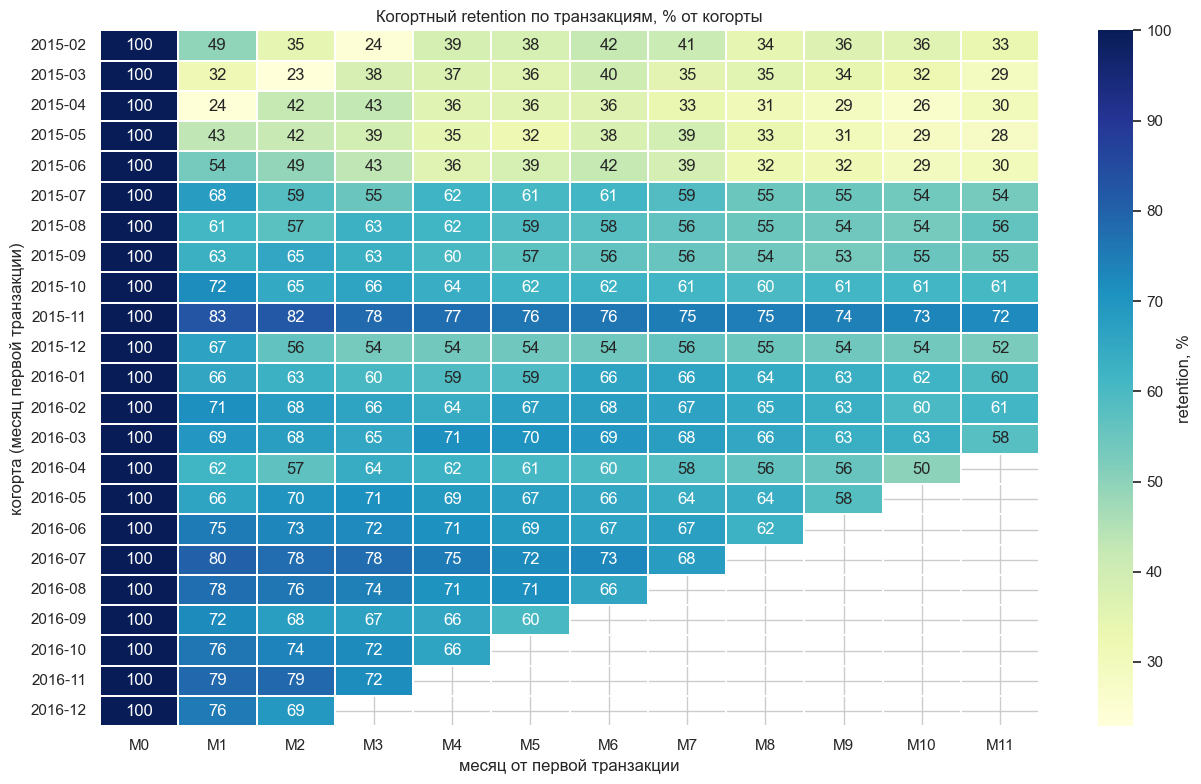

In [5]:
fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(ret * 100, annot=True, fmt='.0f', cmap='YlGnBu',
            mask=ret.isna(), linewidths=0.3, ax=ax,
            cbar_kws={'label': 'retention, %'})
ax.set_title('Когортный retention по транзакциям, % от когорты')
ax.set_xlabel('месяц от первой транзакции')
ax.set_ylabel('когорта (месяц первой транзакции)')
plt.tight_layout()
plt.show()

    подписочный retention  платёжный retention
m                                             
0                  100.00               100.00
1                   98.50                66.50
2                   89.50                63.20
3                   86.30                61.90
4                   84.10                60.80
5                   82.20                59.70
6                   80.90                60.40
7                   78.30                58.80
8                   76.30                56.20
9                   75.10                54.90
10                  74.00                53.60
11                  73.10                53.10


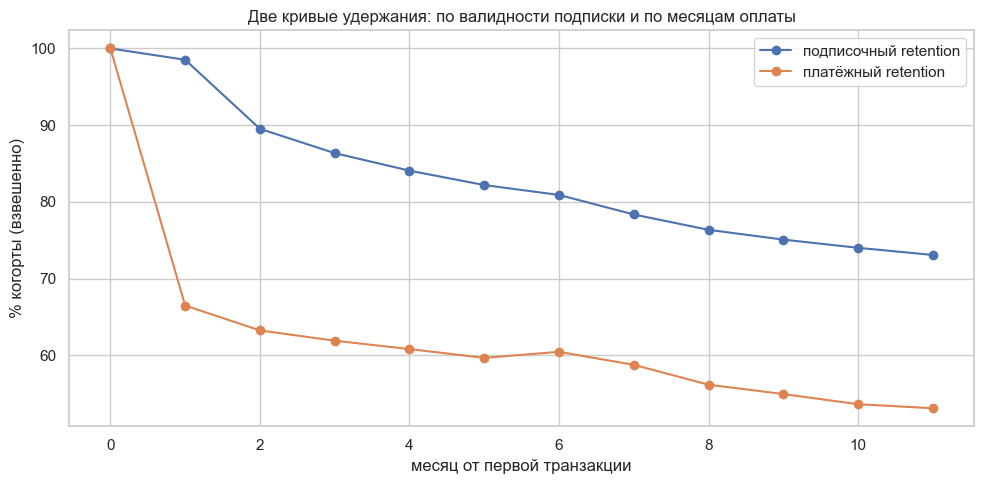

ранние 2015-02..05: <=31д 93.1%, 32-89д 0.2%, >=90д 6.8%
поздние 2016-07..12: <=31д 98.7%, 32-89д 0.0%, >=90д 1.3%


In [6]:

# Подписочная кривая: доля когорты с валидной подпиской в месяце m
vt = tx.loc[(tx.actual_amount_paid > 0) & (tx.payment_plan_days > 0)
            & (tx.membership_expire_date != 19700101),
            ['msno', 'transaction_date', 'membership_expire_date', 'payment_plan_days']].copy()
vt['tx_month'] = vt.transaction_date // 100
vt['exp_month'] = vt.membership_expire_date // 100

cohort0 = vt.groupby('msno', observed=True).tx_month.min().rename('cohort')
last_alive = vt.groupby('msno', observed=True).exp_month.max().rename('last_alive')
u = pd.concat([cohort0, last_alive], axis=1)
u = u[(u.cohort >= 201502) & (u.cohort <= 201612)]

MAX_EXP_MONTH = 201703
rows = []
for co, g in u.groupby('cohort'):
    for m in range(12):
        if month_diff(MAX_EXP_MONTH, co) < m:
            continue
        rows.append((co, m, (g.last_alive.map(lambda e, c=co: month_diff(e, c)) >= m).mean(), len(g)))
S = pd.DataFrame(rows, columns=['cohort', 'm', 's', 'n'])
expire_curve = S.groupby('m').apply(lambda x: np.average(x.s, weights=x.n), include_groups=False)

# Платёжная кривая (взвешенная) для сравнения — из матрицы ячейки выше
pay_ret_full = (cnt / size).unstack()
pay_curve = pay_ret_full.apply(lambda col: np.average(col.dropna(), weights=size[col.dropna().index]))

cmp = pd.DataFrame({'подписочный retention': expire_curve, 'платёжный retention': pay_curve})
print((cmp * 100).round(1).to_string())

ax = (cmp * 100).plot(figsize=(10, 5), marker='o',
                      title='Две кривые удержания: по валидности подписки и по месяцам оплаты')
ax.set_xlabel('месяц от первой транзакции')
ax.set_ylabel('% когорты (взвешенно)')
plt.tight_layout()
plt.show()

# Проверка альтернативной гипотезы: различия когорт объясняются миксом длительностей планов?
vtc = vt.join(cohort0, on='msno')
for label, lo, hi in (('ранние 2015-02..05', 201502, 201505), ('поздние 2016-07..12', 201607, 201612)):
    p = vtc.loc[vtc.cohort.between(lo, hi), 'payment_plan_days']
    print(f'{label}: <=31д {(p <= 31).mean():.1%}, 32-89д {((p > 31) & (p < 90)).mean():.1%}, '
          f'>=90д {(p >= 90).mean():.1%}')


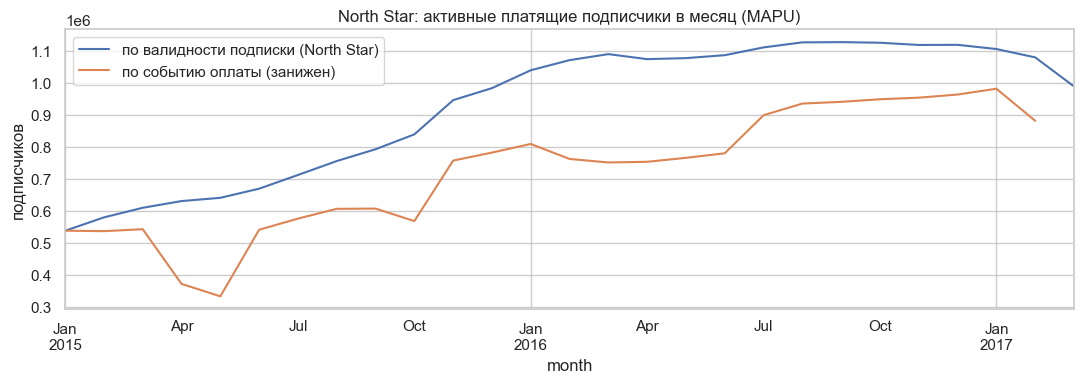

Baseline MAPU (по валидности): 1,079,524 (2017-02); пик 1,127,179 (2016-09)
Транзакционный MAPU занижает метрику на 18% (881,398 vs 1,079,524) — владельцы длинных планов не платят каждый месяц


In [7]:
# MAPU двумя способами: по событию оплаты и по валидности подписки
all_u = pd.concat([vt.groupby('msno', observed=True).tx_month.min().rename('f'),
                   vt.groupby('msno', observed=True).exp_month.max().rename('e')], axis=1)

months_idx = pd.period_range('2014-01', '2017-03', freq='M')
midx = {int(str(p)[:4] + str(p)[5:7]): k for k, p in enumerate(months_idx)}
diff = np.zeros(len(months_idx) + 1)
f_i = all_u.f.map(midx).fillna(12).astype(int).to_numpy()          # 2015-01
e_i = all_u.e.map(midx).fillna(len(months_idx) - 1).astype(int).to_numpy()
np.add.at(diff, f_i, 1)
np.add.at(diff, np.minimum(e_i + 1, len(months_idx)), -1)
# Приближение: покрытие непрерывно от первой оплаты до max expire (разрывы не учитываются)
mapu_cov = pd.Series(np.cumsum(diff)[:-1], index=months_idx.to_timestamp())

mapu_tx = txm.groupby('month').msno.nunique()
mapu_tx.index = pd.to_datetime(mapu_tx.index, format='%Y%m')

fig, ax = plt.subplots(figsize=(11, 4))
mapu_cov.loc['2015-01':].plot(ax=ax, label='по валидности подписки (North Star)')
mapu_tx.plot(ax=ax, label='по событию оплаты (занижен)')
ax.set_title('North Star: активные платящие подписчики в месяц (MAPU)')
ax.set_ylabel('подписчиков')
ax.legend()
plt.tight_layout()
plt.show()

base_cov = int(mapu_cov['2017-02'].iloc[0])
base_tx = int(mapu_tx['2017-02'].iloc[0])
print(f'Baseline MAPU (по валидности): {base_cov:,} (2017-02); пик {int(mapu_cov.max()):,} '
      f'({mapu_cov.idxmax():%Y-%m})')
print(f'Транзакционный MAPU занижает метрику на {(1 - base_tx / base_cov):.0%} '
      f'({base_tx:,} vs {base_cov:,}) — владельцы длинных планов не платят каждый месяц')

**Выводы по retention.**
- **Подписочная кривая (основная)**: M1 = 98,5%, M3 = 86%, M6 = 81%, M11 = 73% (взвешенно по размерам когорт) — подписка действительно липкая: почти вся когорта покрыта подпиской и через полгода.
- **Платёжная кривая (диагностическая)**: взвешенный M1 = 66,5%, M3 = 62%, M6 = 60%. Разрыв между кривыми (~20–25 п.п.) — это владельцы длинных планов: они удержаны, но не платят ежемесячно. Именно поэтому платёжная метрика годится только как диагностика платёжной активности, а не как мера удержания (в строках платёжной матрицы видны «воскрешения» — рост доли оплат в M3/M6 при планах 90/180 дней).
- Ранние когорты 2015-02 — 2015-05 слабее по платёжной кривой (M1 = 24–49%). Проверка альтернативной гипотезы показала: у ранних когорт доля планов ≥90 дней — 6,8% против 1,3% у поздних, т.е. часть разрыва объясняется миксом длительностей планов, а не качеством привлечения. Вывод о «провале промо» смягчаем до гипотезы: ранние промо-когорты хуже по платёжной активности, но разница в подписочном удержании частично артефакт тарифной сетки.

### 7.2. LTV / CAC

LTV считаем **когортным интегралом** по подписочной кривой удержания: LTV = ARPPU × маржа × ΣS(m), где S(m) — доля когорты с валидной подпиской в месяце m (ячейка 7.1). Усечение на 24 месяцах и сглаженный хвост — консервативные допущения. Наивная формула ARPPU×маржа/churn отвергнута на методологическом разборе: churn из `train` измерен на дожившей до экспирации базе и не является месячной ставкой оттока новых пользователей. Данных о расходах на привлечение и маржинальности нет (зафиксированное ограничение) — маржа и CAC задаются допущениями, считаем сценарии.

In [8]:
valid = tx[(tx.actual_amount_paid > 0) & (tx.payment_plan_days > 0)]
monthly_price = valid.actual_amount_paid / valid.payment_plan_days * 30
arppu_mean, arppu_median = monthly_price.mean(), monthly_price.median()

train = pd.read_csv(TRAIN)
churn_exp = train.is_churn.mean()      # churn на экспирации (риск-метрика), НЕ месячная ставка
MARGIN = 0.25                          # допущение: валовая маржа стриминга ~25%

# Когортный интеграл по подписочной кривой S(m), усечение 24 мес + сглаженный хвост
tail_decay = (expire_curve.loc[11] / expire_curve.loc[6]) ** (1 / 5)
S_ext = [expire_curve.loc[m] if m < 12 else expire_curve.loc[11] * tail_decay ** (m - 11)
         for m in range(24)]
sumS = sum(S_ext)
ltv = arppu_mean * MARGIN * sumS
ltv_disc = arppu_mean * MARGIN * sum(x / 1.01 ** m for m, x in enumerate(S_ext))

paying_users = valid.msno.nunique()
hist_rev_per_user = valid.actual_amount_paid.sum() / paying_users

# Конверсия по определению: регистрации в окне, первая оплата не раньше регистрации
mem_conv = members[members.registration_init_time <= 20170228].copy()
mem_conv['reg_month'] = mem_conv.registration_init_time // 100
mm = mem_conv.set_index('msno').join(all_u.f.rename('first_tx'))
conv = (mm.first_tx.notna() & (mm.first_tx >= mm.reg_month)).mean()

print(f'ARPPU в месяц: mean = {arppu_mean:.0f} NTD, median = {arppu_median:.0f} NTD')
print(f'Подписочная кривая: сумма S(0..23) = {sumS:.1f} подписочных месяцев '
      f'(затухание хвоста {tail_decay:.1%}/мес по сегменту M6->M11)')
print(f'LTV_24 = {arppu_mean:.0f} x {MARGIN} x {sumS:.1f} = {ltv:.0f} NTD '
      f'(с дисконтом 1%/мес: {ltv_disc:.0f} NTD)')
print(f'Проверка непротиворечивости: реализованная маржа на платящего за 26 мес = '
      f'{hist_rev_per_user * MARGIN:.0f} NTD — правая цензура делает её нижней границей, '
      f'LTV обязан быть выше: {ltv:.0f} > {hist_rev_per_user * MARGIN:.0f} — непротиворечиво')
print(f'Конверсия регистрация -> оплата: {conv:.1%} '
      f'(регистрации <= 2017-02, первая оплата не раньше регистрации)')
print(f'Churn на экспирации (риск-метрика, train): {churn_exp:.2%} '
      f'— в расчёте LTV не используется')

cacs = [150, 300, 450]          # NTD ~ $5 / $10 / $15 — допущения
margins = [0.15, 0.25, 0.35]
scen = pd.DataFrame(
    {f'CAC {c}': [arppu_mean * g * sumS / c for g in margins] for c in cacs},
    index=[f'маржа {g:.0%}' for g in margins],
).round(2)
print('\nСценарии LTV/CAC (когортный LTV_24, mean ARPPU):')
scen

ARPPU в месяц: mean = 135 NTD, median = 149 NTD
Подписочная кривая: сумма S(0..23) = 17.7 подписочных месяцев (затухание хвоста 98.0%/мес по сегменту M6->M11)
LTV_24 = 135 x 0.25 x 17.7 = 598 NTD (с дисконтом 1%/мес: 540 NTD)
Проверка непротиворечивости: реализованная маржа на платящего за 26 мес = 422 NTD — правая цензура делает её нижней границей, LTV обязан быть выше: 598 > 422 — непротиворечиво
Конверсия регистрация -> оплата: 23.0% (регистрации <= 2017-02, первая оплата не раньше регистрации)
Churn на экспирации (риск-метрика, train): 6.39% — в расчёте LTV не используется

Сценарии LTV/CAC (когортный LTV_24, mean ARPPU):


,CAC 150,CAC 300,CAC 450
маржа 15%,2.39,1.20,0.80
маржа 25%,3.99,1.99,1.33
маржа 35%,5.58,2.79,1.86


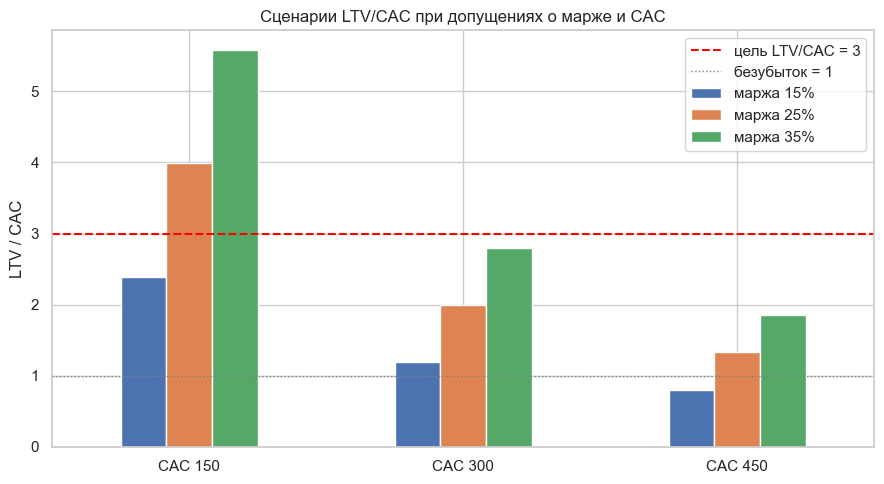

In [9]:
ax = scen.T.plot(kind='bar', figsize=(9, 5), rot=0)
ax.axhline(3, color='red', ls='--', lw=1.5, label='цель LTV/CAC = 3')
ax.axhline(1, color='gray', ls=':', lw=1, label='безубыток = 1')
ax.set_ylabel('LTV / CAC')
ax.set_title('Сценарии LTV/CAC при допущениях о марже и CAC')
ax.legend()
plt.tight_layout()
plt.show()

**Выводы по LTV/CAC.**
- **LTV_24 ≈ 598 NTD** (ARPPU 135 NTD × маржа 25% × 17,7 подписочных месяцев; с дисконтом 1%/мес — 540 NTD). Метод — когортный интеграл по подписочной кривой; усечение на 24 месяцах занижает оценку (консервативно).
- Наивная оценка через churn из train (529 NTD) отклонена методологически: 6,4% — churn на экспирацию дожившей базы, а не ставка оттока новых когорт; совпадение чисел (529 vs 598) случайно, доверять следует интегралу.
- Проверка непротиворечивости: реализованная маржа на платящего (422 NTD за всё окно) — цензурированная нижняя граница; LTV выше неё, как и должно быть.
- Юнит-экономика сходится (LTV/CAC ≥ 3) при **CAC ≲ 200 NTD (~$6–7)** при марже 25%; при CAC 300+ NTD требуется маржа 30%+ или рост ARPPU.
- Ограничение: CAC — внешнее допущение (бенчмарк music-streaming SEA ~$5–15), согласуется с преподавателем; данных о расходах в датасете нет.

### 7.3. (Опционально) Дневная активность по логам прослушиваний

Файл `user_logs_v1.csv` — 28 ГБ, полный проход занимает десятки минут. Ячейка ниже выключена (`RUN_LOGS_SCAN = False`); при включении считает DAU по случайной выборке 100 тыс. пользователей и кеширует результат в `data/cache/`. Для сдачи трека Б не требуется.

In [10]:
if RUN_LOGS_SCAN:
    import time
    os.makedirs(os.path.join(DATA, 'cache'), exist_ok=True)
    cache = os.path.join(DATA, 'cache', 'dau_sample.pkl')
    if os.path.exists(cache):
        daily = pd.read_pickle(cache)
    else:
        rng = np.random.default_rng(42)
        sample_users = set(rng.choice(members.msno.values,
                                      size=min(LOG_SAMPLE_USERS, len(members)),
                                      replace=False))
        t0 = time.time()
        counts = {}
        for chunk in pd.read_csv(USER_LOGS, usecols=['msno', 'date'],
                                 chunksize=5_000_000):
            sub = chunk[chunk.msno.isin(sample_users)]
            for d, n in sub.groupby('date').msno.nunique().items():
                counts[d] = counts.get(d, 0) + n
        daily = pd.Series(counts).sort_index()
        daily.index = pd.to_datetime(daily.index, format='%Y%m%d')
        pd.to_pickle(daily, cache)
        print(f'Скан занял {time.time()-t0:.0f} c')
    ax = daily.rolling(7).mean().plot(figsize=(12, 4),
        title=f'DAU (выборка {LOG_SAMPLE_USERS:,} пользователей, скользящее среднее 7д)')
    ax.set_ylabel('активных пользователей в день')
    plt.tight_layout()
    plt.show()
else:
    print('Пропущено (RUN_LOGS_SCAN = False).')

Пропущено (RUN_LOGS_SCAN = False).


## 8. Этика (краткий комментарий, трек Б)

- **Цель:** учебный анализ оттока и юнит-экономики; данные не используются для решений о конкретных людях.
- **Согласие и происхождение:** данные собраны и обезличены владельцем (KKBox) и опубликованы для конкурса WSDM/Kaggle; идентификатор `msno` — хэш, персональные данные отсутствуют, восстановление личности невозможно и не предпринимается.
- **Специальные категории:** отсутствуют; пол/возраст частично повреждены и в выводах не используются для профилирования.
- **Передача третьим лицам:** не планируется; сырые данные не публикуются (`.gitignore`), в репозитории — ссылка на первоисточник.
- **Хранение и удаление:** локальное хранение на время проекта; удаление по завершении не требует процедур — данных, привязанных к личности, нет.

## 9. Критерии успеха (к финалу проекта)

| Метрика | Baseline (этот ноутбук) | Цель | Способ проверки |
|---|---|---|---|
| MAPU (North Star, по валидности подписки) | 1 079 524 (2017-02), пик 1 127 179 (2016-09) | ≥ 1,3 млн (+20% к baseline) | пересчёт покрытия на окне v2 (март 2017) |
| M3 подписочное удержание новых когорт | 86% (взвешенно) | ≥ 88% | пересчёт подписочной кривой на окне v2 |
| LTV/CAC | LTV_24 = 598 NTD → 3,0 при CAC = 200 NTD | ≥ 3 при подтверждённом CAC | сценарный пересчёт с уточнёнными CAC/маржой |
| Churn на экспирации (риск-метрика) | 6,4% | ≤ 5,5% | пересчёт метки на отложенном окне |

## 10. Итоги и ограничения

- Датасет KKBox подтверждён как подходящий: 6,77 млн пользователей, 21,5 млн транзакций, дневные логи за 26 месяцев, готовое правило оттока, реалистичные дефекты.
- Определения уточнены по итогам методологического разбора (erratum S1): подписчик считается по валидности подписки, удержание — двумя кривыми (подписочная основная, платёжная диагностическая).
- Подписочное удержание: M1 = 98,5%, M3 = 86%, плато ~73% к M11. North Star (MAPU) на baseline: 1,08 млн платящих подписчиков (2017-02) — транзакционная версия метрики занижала его на ~18%.
- LTV_24 ≈ 598 NTD когортным интегралом (ARPPU 135 NTD, маржа 25% — допущение); юнит-экономика сходится при CAC ≲ 200 NTD; churn на экспирации 6,4%.
- **Ограничения:** нет расходов на привлечение и маржи в данных (CAC — допущение, согласуется с преподавателем); MAPU по покрытию — приближение (разрывы подписки между первой оплатой и max expire не учитываются); вывод о промо-когортах — гипотеза (часть эффекта объясняется миксом длительностей планов); поле возраста непригодно; расчёты на окне v1 (v2 не распаковалось).

**Вклад участников:** проект индивидуальный (трек Б), все разделы выполнены автором.